In [2]:
#importing lib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [3]:
data = pd.read_csv("data/EE467_EDA_Data_Group16_Load.csv")
print("Shape:", data.shape)
display(data.head())
print(data.columns)

data["Timestamp"] = pd.to_datetime(data["Timestamp"], utc=True)
data.set_index("Timestamp", inplace=True)
print("Shape:", data.shape)
display(data.head())
print(data.columns)

Shape: (35064, 2)


,Timestamp,Value (MW)
0,2015-01-01T00:00:00+0100,NaN
1,2015-01-01T01:00:00+0100,NaN
2,2015-01-01T02:00:00+0100,3100.02
3,2015-01-01T03:00:00+0100,2980.39
4,2015-01-01T04:00:00+0100,2933.49


Index(['Timestamp', 'Value (MW)'], dtype='object')
Shape: (35064, 1)


,Value (MW)
Timestamp,
2014-12-31 23:00:00+00:00,NaN
2015-01-01 00:00:00+00:00,NaN
2015-01-01 01:00:00+00:00,3100.02
2015-01-01 02:00:00+00:00,2980.39
2015-01-01 03:00:00+00:00,2933.49


Index(['Value (MW)'], dtype='object')


In [4]:
#checking data or cleaning
print(data.isna().sum())        # count missing values per column
print(data.isna().mean()*100)   # percentage missing

print(data.index.duplicated().sum())   # check duplicate timestamps
print(data.index.min(), data.index.max())


Value (MW)    2
dtype: int64
Value (MW)    0.005704
dtype: float64
0
2014-12-31 23:00:00+00:00 2018-12-31 22:00:00+00:00


In [5]:
#cleaning
data = data.dropna()
print("Shape:", data.shape)
display(data.head())
print(data.columns)

print("\nSummary Statistics:")
display(data.describe())

Shape: (35062, 1)


,Value (MW)
Timestamp,
2015-01-01 01:00:00+00:00,3100.02
2015-01-01 02:00:00+00:00,2980.39
2015-01-01 03:00:00+00:00,2933.49
2015-01-01 04:00:00+00:00,2941.54
2015-01-01 05:00:00+00:00,2999.89


Index(['Value (MW)'], dtype='object')

Summary Statistics:


,Value (MW)
count,35062.000000
mean,3741.028379
std,752.187485
min,2099.740000
25%,3120.895000
50%,3707.270000
75%,4337.965000
max,8607.380000


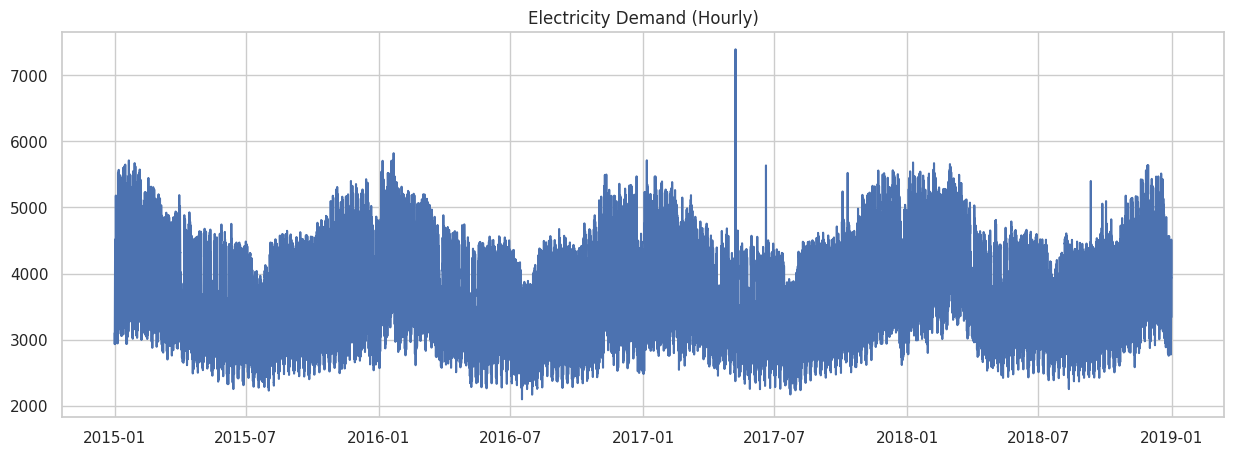

2


In [7]:
#Visual inspection
plt.figure(figsize=(15,5))
plt.plot(data["Value (MW)"])
plt.title("Electricity Demand (Hourly)")
plt.show()

z_scores = (data["Value (MW)"] - data["Value (MW)"].mean()) / data["Value (MW)"].std()
print((abs(z_scores) > 3).sum())

#remoing outliers
rolling_median = data["Value (MW)"].rolling(window=3, center=True).median()
data["Value (MW)"] = np.where(abs(z_scores) > 3, rolling_median, data["Value (MW)"])


ADF Statistic: -16.460750771555027
ADF p-value: 2.3314168121246268e-29
KPSS Statistic: 0.9941391759938167
KPSS p-value: 0.01


/tmp/ipython-input-3077247656.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(series, regression='c')


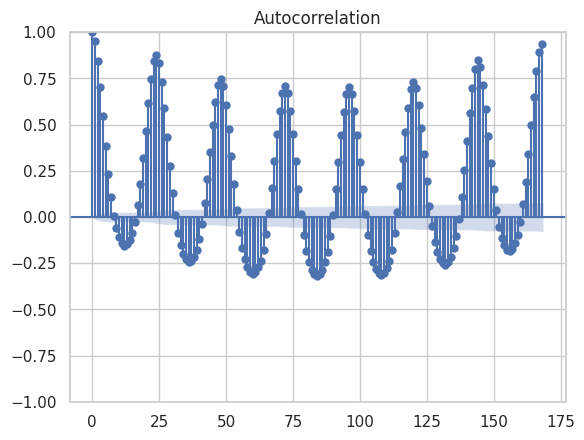

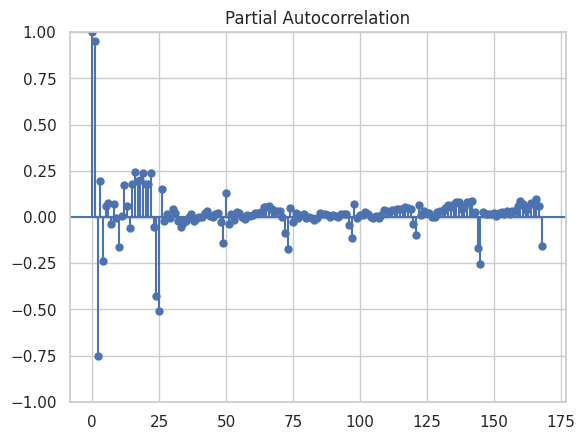

In [8]:
#seasonality test
from statsmodels.tsa.stattools import adfuller, kpss

series = data["Value (MW)"].dropna()

adf_result = adfuller(series)
print("ADF Statistic:", adf_result[0])
print("ADF p-value:", adf_result[1])

kpss_result = kpss(series, regression='c')
print("KPSS Statistic:", kpss_result[0])
print("KPSS p-value:", kpss_result[1])

#seasonality
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(series, lags=24*7)
plt.show()

plot_pacf(series, lags=24*7)
plt.show()




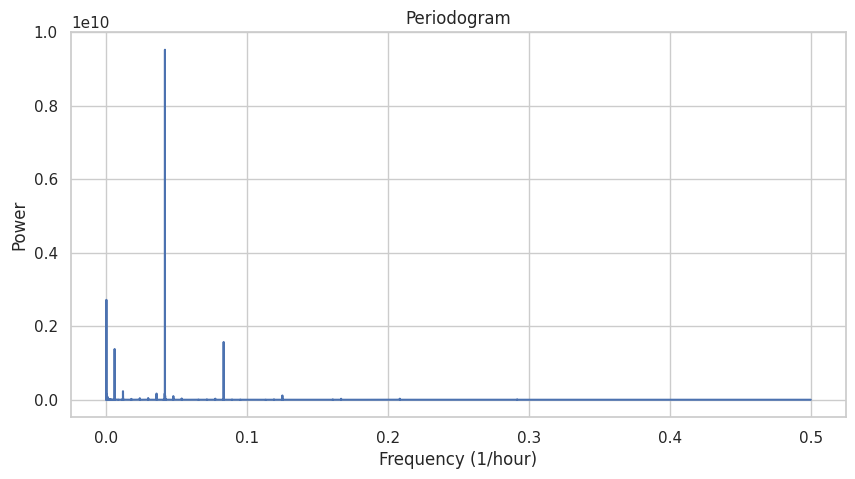

In [9]:
from scipy.signal import periodogram

freqs, power = periodogram(series, fs=1)  # fs=1 since hourly
plt.figure(figsize=(10,5))
plt.plot(freqs, power)
plt.title("Periodogram")
plt.xlabel("Frequency (1/hour)")
plt.ylabel("Power")
plt.show()

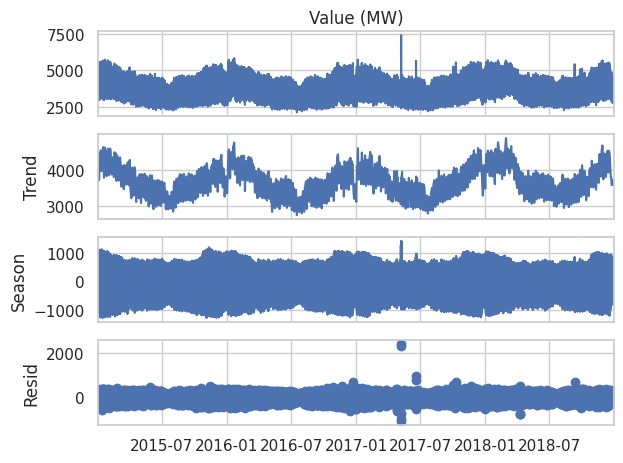

In [10]:
from statsmodels.tsa.seasonal import STL

stl = STL(series, period=24)  # period=24 for daily seasonality
result = stl.fit()

fig = result.plot()
plt.show()

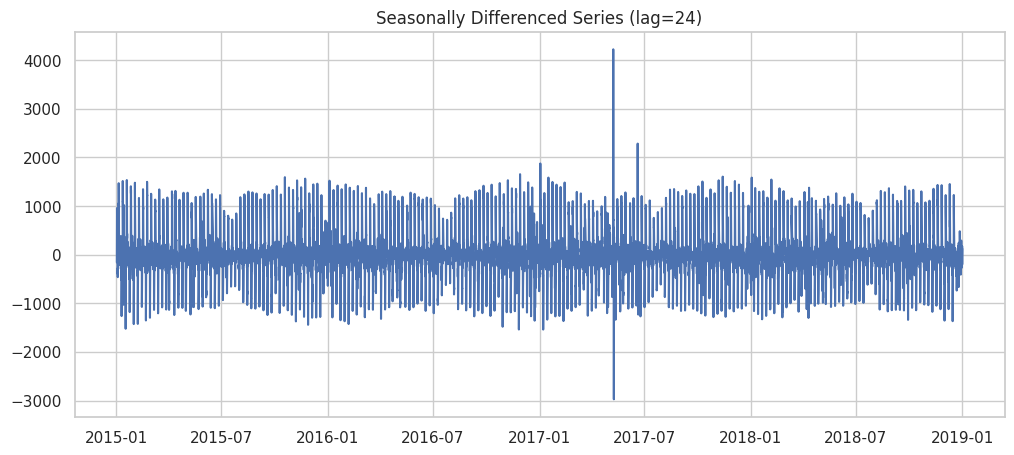

In [11]:
seasonal_diff = series.diff(24).dropna()
plt.figure(figsize=(12,5))
plt.plot(seasonal_diff)
plt.title("Seasonally Differenced Series (lag=24)")
plt.show()

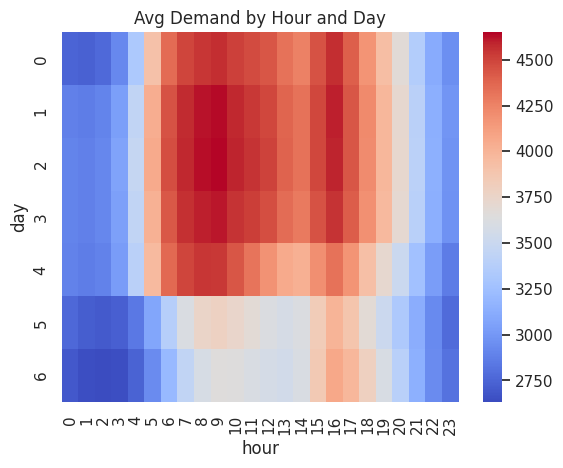

In [12]:
# Heatmap: Hour vs Day
data["hour"] = data.index.hour
data["day"] = data.index.dayofweek
pivot = data.pivot_table(index="day", columns="hour", values="Value (MW)", aggfunc="mean")
sns.heatmap(pivot, cmap="coolwarm")
plt.title("Avg Demand by Hour and Day")
plt.show()

In [13]:
import pandas as pd

# Load the data
df = pd.read_csv("data/EE467_EDA_Data_Group16_Load.csv", parse_dates=["Timestamp"])
df = df.set_index("Timestamp")

# Check for missing values and drop them
df = df.dropna()

# Rename for convenience
series = df["Value (MW)"]


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:             Value (MW)   No. Observations:                35062
Model:                 ARIMA(5, 1, 0)   Log Likelihood             -228581.998
Date:                Thu, 21 Aug 2025   AIC                         457175.996
Time:                        09:17:30   BIC                         457226.785
Sample:                             0   HQIC                        457192.172
                              - 35062                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7852      0.001    547.398      0.000       0.782       0.788
ar.L2         -0.2088      0.001   -182.484      0.000      -0.211      -0.207
ar.L3          0.0659      0.002     34.129      0.0

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


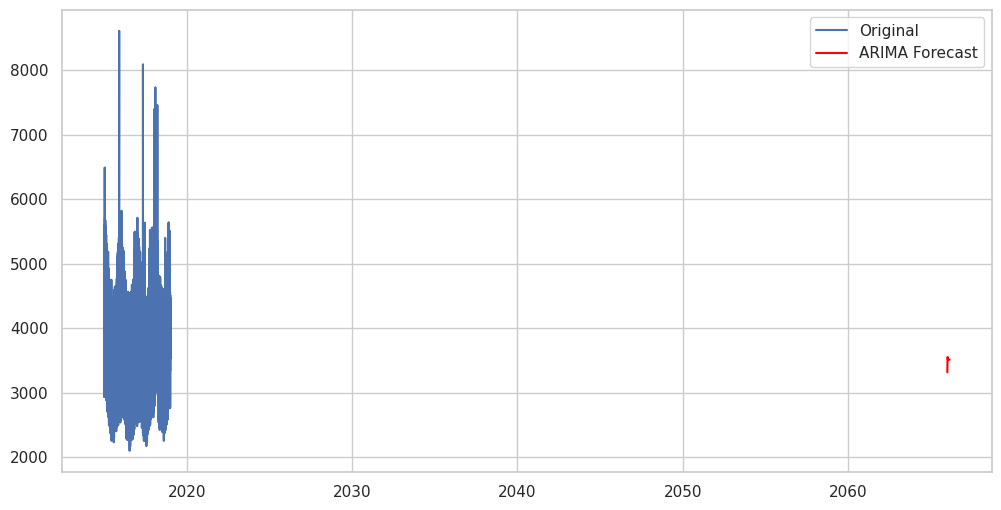

In [14]:
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt

# Fit ARIMA model (example order, tune as needed)
model_arima = ARIMA(series, order=(5,1,0))  # p=5, d=1, q=0
model_arima_fit = model_arima.fit()

# Summary of the model
print(model_arima_fit.summary())

# Forecast the next 50 points
forecast_arima = model_arima_fit.forecast(steps=50)

# Plot original series and forecast
plt.figure(figsize=(12,6))
plt.plot(series, label="Original")
plt.plot(forecast_arima.index, forecast_arima, label="ARIMA Forecast", color='red')
plt.legend()
plt.show()


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                         Value (MW)   No. Observations:                35062
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 24)   Log Likelihood             -210172.208
Date:                            Thu, 21 Aug 2025   AIC                         420354.417
Time:                                    09:20:05   BIC                         420396.737
Sample:                                         0   HQIC                        420367.896
                                          - 35062                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0266      0.004     -5.940      0.000      -0.035      -0.018
ma.L1          0.2171      0.004   

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


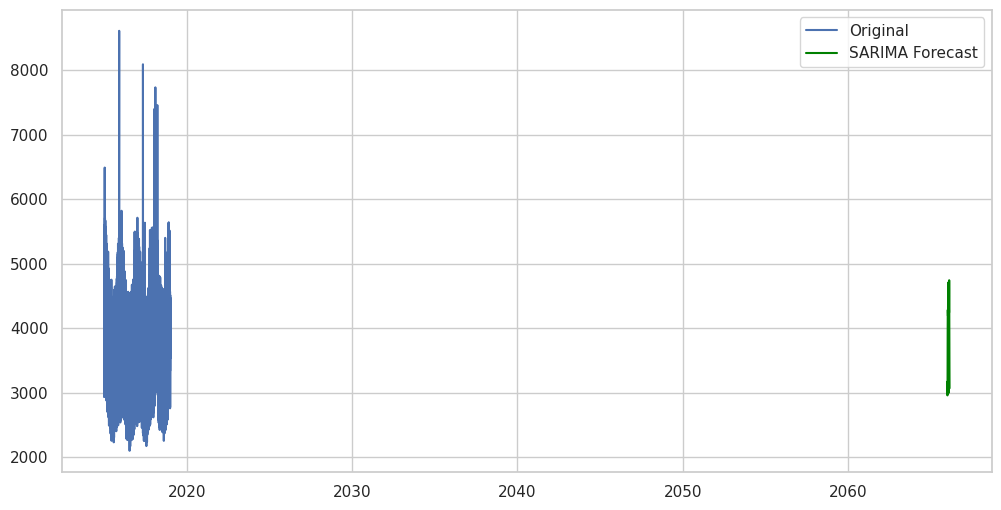

In [15]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Fit SARIMA model (example order values)
model_sarima = SARIMAX(series, order=(1,1,1), seasonal_order=(1,1,1,24))
model_sarima_fit = model_sarima.fit()

# Summary of the model
print(model_sarima_fit.summary())

# Forecast the next 50 points
forecast_sarima = model_sarima_fit.get_forecast(steps=50)
forecast_sarima_values = forecast_sarima.predicted_mean

# Plot original series and forecast
plt.figure(figsize=(12,6))
plt.plot(series, label="Original")
plt.plot(forecast_sarima_values.index, forecast_sarima_values, label="SARIMA Forecast", color='green')
plt.legend()
plt.show()


In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import SimpleImputer

# Load the data
data = pd.read_csv("data/EE467_EDA_Data_Group16_Load.csv")

# Convert Timestamp to datetime type
data['Timestamp'] = pd.to_datetime(data['Timestamp'], utc=True)

# Drop rows with NaN target values or alternatively impute them
data = data.dropna(subset=['Value (MW)'])

# Feature engineering: extract datetime features
data['hour'] = data['Timestamp'].dt.hour
data['dayofweek'] = data['Timestamp'].dt.dayofweek
data['month'] = data['Timestamp'].dt.month
data['day'] = data['Timestamp'].dt.day

# Define features and target
X = data[['hour', 'dayofweek', 'month', 'day']]
y = data['Value (MW)']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Predict on test data
y_pred = rf_model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Random Forest Regression Results")
print(f"RMSE: {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")


Random Forest Regression Results
RMSE: 158.414
R2 Score: 0.955
